# Exercises XP: Text Preprocessing, NER, POS, and Word2Vec

Use this guided notebook to follow the platform instructions step by step. Prefilled cells are ready to run; cells marked TODO expect your code or analysis.

## What you will learn
- Clean and normalize raw reviews with tokenization, stopword removal, and lemmatization.
- Extract linguistic features with named entity recognition (NER) and part-of-speech (POS) tagging.
- Train a simple Word2Vec model and interpret its vector dimensions.
- Visualize word embeddings to reason about semantic neighborhoods.

## What you will create
- A `preprocess_text` function that lowercases, strips punctuation, removes stopwords, and lemmatizes.
- `perform_ner` and `perform_pos_tagging` helpers to analyze raw vs cleaned text.
- A Word2Vec model plus a helper to plot embeddings for inspection.

> Learning point
> Run the setup cells once, then progress through each exercise sequentially. Print intermediate results to verify every helper works before moving on.

## Setup · install libraries
Run once to install spaCy, nltk, gensim, and plotting utilities.

In [1]:
%pip install --quiet spacy nltk gensim matplotlib seaborn --upgrade

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import nltk
from spacy.cli import download as spacy_download
import spacy

resources = [
    "punkt",
    "punkt_tab",
    "wordnet",
    "omw-1.4",
    "stopwords",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "tagsets",
]
for res in resources:
    nltk.download(res, quiet=True)

spacy_download("en_core_web_sm")

nlp = spacy.load("en_core_web_sm")
print("spaCy pipeline:", nlp.pipe_names)


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


## Exercise 1 · Explore text preprocessing, NER, and POS tags

Here is the dataset you will reuse in every step.

In [1]:
data = {
    'Review': [
        "At McDonald's the food was ok and the service was bad.",
        "I would not recommend this Japanese restaurant to anyone.",
        "I loved this restaurant when I traveled to Thailand last summer.",
        "The menu of Loving has a wide variety of options.",
        "The staff was friendly and helpful at Google's employees restaurant.",
        "The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",
        "I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.",
        "The sushi at Sushi Express is always fresh and flavorful.",
        "The steakhouse on Main Street has a cozy atmosphere and excellent steaks.",
        "The dessert selection at Sweet Treats is to die for!"
    ]
}
raw_reviews = data['Review']
raw_reviews


["At McDonald's the food was ok and the service was bad.",
 'I would not recommend this Japanese restaurant to anyone.',
 'I loved this restaurant when I traveled to Thailand last summer.',
 'The menu of Loving has a wide variety of options.',
 "The staff was friendly and helpful at Google's employees restaurant.",
 'The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.',
 'I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.',
 'The sushi at Sushi Express is always fresh and flavorful.',
 'The steakhouse on Main Street has a cozy atmosphere and excellent steaks.',
 'The dessert selection at Sweet Treats is to die for!']

### 1.1 Build `preprocess_text()`
Create a function that:
1. Lowercases and tokenizes text.
2. Removes punctuation tokens.
3. Removes English stopwords.
4. Applies a lemmatizer.
5. Returns the cleaned string joined by spaces.

Print the processed reviews to confirm every stage works.

In [12]:
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    """Lowercase, tokenize, strip punctuation, drop stopwords, and lemmatize a review."""
    # TODO: tokenize the text (hint: nltk.word_tokenize)
    # TODO: remove punctuation tokens
    # TODO: filter out stopwords
    # TODO: lemmatize remaining tokens
    # TODO: join back into a single cleaned string

    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in string.punctuation]
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)


### 1.2 Create a cleaned dataset
Apply `preprocess_text` to every review and keep both raw and cleaned versions side by side.

In [13]:
# TODO: apply preprocess_text to every review and keep both raw and cleaned versions
cleaned_reviews = []
for d in data['Review']:
    # print(type(d))
    cleaned_reviews.append(preprocess_text(d))

for raw, cleaned in zip(raw_reviews, cleaned_reviews):
    print(f"RAW: {raw}")
    print(f"CLEANED: {cleaned}\n")


RAW: At McDonald's the food was ok and the service was bad.
CLEANED: mcdonald 's food ok service bad

RAW: I would not recommend this Japanese restaurant to anyone.
CLEANED: would recommend japanese restaurant anyone

RAW: I loved this restaurant when I traveled to Thailand last summer.
CLEANED: loved restaurant traveled thailand last summer

RAW: The menu of Loving has a wide variety of options.
CLEANED: menu loving wide variety option

RAW: The staff was friendly and helpful at Google's employees restaurant.
CLEANED: staff friendly helpful google 's employee restaurant

RAW: The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.
CLEANED: ambiance bella italia amazing pasta dish delicious

RAW: I had a terrible experience at Pizza Hut. The pizza was burnt, and the service was slow.
CLEANED: terrible experience pizza hut pizza burnt service slow

RAW: The sushi at Sushi Express is always fresh and flavorful.
CLEANED: sushi sushi express always fresh flavorful

RAW

### 1.3 Named Entity Recognition (NER)
Create `perform_ner(text)` that returns `(entity, label_)` pairs using `en_core_web_sm`. Test it on a few reviews.

In [17]:
import spacy

def perform_ner(text: str):
    """Return (entity, label) pairs found by spaCy."""
    # TODO: run the spaCy pipeline on the text
    # TODO: collect each entity text and its label_

    nlp = spacy.load("en_core_web_sm")
    return [(e.text, e.label_) for e in nlp(text).ents]


### 1.4 Part-of-Speech tagging (POS)
Create `perform_pos_tagging(text)` using `nltk.pos_tag`. Test it on both raw and cleaned text.

Use `nltk.help.upenn_tagset('NN')` to recall tag meanings if needed.

In [19]:
from nltk import pos_tag, word_tokenize

def perform_pos_tagging(text: str):
    """Return POS tags for a given text."""
    # TODO: tokenize the text
    # TODO: call nltk.pos_tag on the tokens
    
    tokens = word_tokenize(text)
    return pos_tag(tokens)

### 1.5 Apply NER and POS on raw vs cleaned text
Compare outputs on the same entries to see how preprocessing affects tagging.

In [27]:
sample_texts = raw_reviews[:2]
cleaned_texts = cleaned_reviews[:2]

print("NER on raw text")
for t in sample_texts:
    print(perform_ner(t))

print("\nNER on cleaned text")
for t in cleaned_texts:
    print(perform_ner(t))

print("\nPOS tags on raw text")
for t in sample_texts:
    print(perform_pos_tagging(t))

print("\nPOS tags on cleaned text")
for t in cleaned_texts:
    print(perform_pos_tagging(t))


NER on raw text
[('McDonald', 'ORG')]
[('Japanese', 'NORP')]

NER on cleaned text
[("mcdonald 's food ok service", 'ORG')]
[('japanese', 'NORP')]

POS tags on raw text
[('At', 'IN'), ('McDonald', 'NNP'), ("'s", 'POS'), ('the', 'DT'), ('food', 'NN'), ('was', 'VBD'), ('ok', 'JJ'), ('and', 'CC'), ('the', 'DT'), ('service', 'NN'), ('was', 'VBD'), ('bad', 'JJ'), ('.', '.')]
[('I', 'PRP'), ('would', 'MD'), ('not', 'RB'), ('recommend', 'VB'), ('this', 'DT'), ('Japanese', 'JJ'), ('restaurant', 'NN'), ('to', 'TO'), ('anyone', 'NN'), ('.', '.')]

POS tags on cleaned text
[('mcdonald', 'NN'), ("'s", 'POS'), ('food', 'NN'), ('ok', 'JJ'), ('service', 'NN'), ('bad', 'JJ')]
[('would', 'MD'), ('recommend', 'VB'), ('japanese', 'JJ'), ('restaurant', 'NN'), ('anyone', 'NN')]


## Exercise 2 · Plotting word embeddings

### 2.1 Train a Word2Vec model
Vectorize the preprocessed/tokenized dataset with `Word2Vec` from `gensim.models`. Reuse the cleaned text and adjust parameters like `vector_size`, `window`, and `sg`.

In [38]:
from gensim.models import Word2Vec

clean_reviews = [preprocess_text(r) for r in data['Review']]

tokenized_reviews = [review.split() for review in clean_reviews]

w2v = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=50,   # length of each word's list of numbers
    window=3,         # how many words either side count as "context"
    min_count=1,      # keep every word (normally 5+)
    sg=1,             # skip-gram
    epochs=100,
    seed=42, workers=1,
)



### 2.2 Inspect embedding dimensions
Print and interpret the vector size and vocabulary size from the fitted model.

In [37]:
# TODO: print the vector size and vocabulary size of your model


print(f"Vocabulary: {len(w2v.wv)} words, {w2v.wv.vector_size} numbers each\n")
print("First 8 numbers for 'sushi':")
print(w2v.wv['sushi'][:8].round(3))

print("\nWords Word2Vec thinks are closest to 'sushi':")
for w, score in w2v.wv.most_similar('sushi', topn=5):
    print(f"  {w:12} {score:.3f}")


Vocabulary: 56 words, 50 numbers each

First 8 numbers for 'sushi':
[ 0.01  -0.014 -0.006 -0.001  0.    -0.018  0.001 -0.012]

Words Word2Vec thinks are closest to 'sushi':
  atmosphere   0.388
  variety      0.314
  fresh        0.299
  recommend    0.289
  helpful      0.280


### 2.3 Plot word embeddings
Complete `plot_word_embeddings(model)` to scatter-plot the first two dimensions of the learned vectors and annotate each point with its word. Discuss whether related words cluster together.

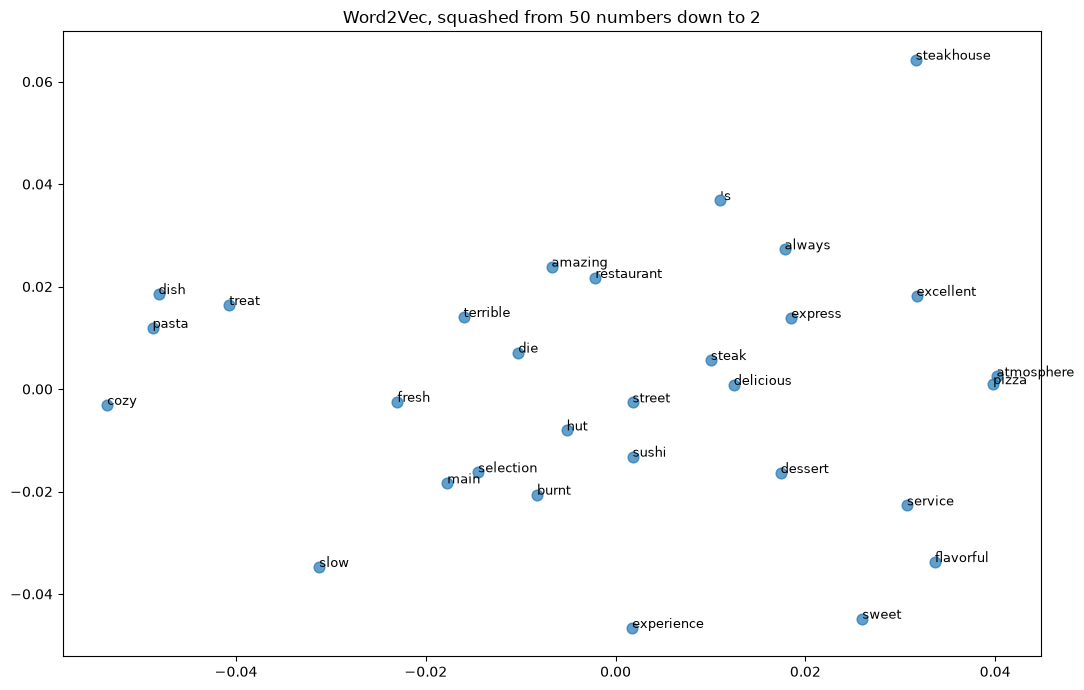

array([[-0.00213095,  0.02167003],
       [ 0.00180008, -0.01320849],
       [ 0.03978415,  0.00094658],
       [ 0.03071333, -0.02271585],
       [ 0.01102318,  0.036862  ],
       [-0.01025003,  0.00710587],
       [-0.04071143,  0.01639   ],
       [ 0.02600955, -0.04483884],
       [-0.01446967, -0.01625836],
       [ 0.01740338, -0.01640932],
       [ 0.01005036,  0.00565881],
       [ 0.03171428,  0.01818505],
       [ 0.04014598,  0.0024526 ],
       [-0.05357172, -0.00309677],
       [ 0.0017871 , -0.00260639],
       [-0.01773928, -0.01841241],
       [ 0.03163406,  0.06427838],
       [ 0.03365409, -0.03378024],
       [-0.02299151, -0.0024959 ],
       [ 0.01781161,  0.0272601 ],
       [ 0.01850103,  0.0138809 ],
       [-0.03122069, -0.03473807],
       [-0.00827638, -0.02062231],
       [-0.00515099, -0.00808641],
       [ 0.00174293, -0.04663761],
       [-0.01601198,  0.01406018],
       [ 0.01245593,  0.00079607],
       [-0.04816303,  0.01853211],
       [-0.04879143,

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_word_embeddings(model, words=None):
    # Default: the 30 most frequent words in the vocabulary
    if words is None:
        words = list(model.wv.key_to_index)[:30]

    # Keep only words the model actually knows
    words = [w for w in words if w in model.wv.key_to_index]

    vectors = np.array([model.wv[w] for w in words])
    coords = PCA(n_components=2).fit_transform(vectors)

    plt.figure(figsize=(11, 7))
    plt.scatter(coords[:, 0], coords[:, 1], s=60, alpha=.7)
    for i, word in enumerate(words):
        plt.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=9)
    plt.title(f"Word2Vec, squashed from {vectors.shape[1]} numbers down to 2")
    plt.tight_layout()
    plt.show()

    return coords


# Call it with your trained model
plot_word_embeddings(w2v)

### 2.4 Go further
- Experiment with different preprocessing (e.g., bigrams, stemming vs lemmatization).
- Tune Word2Vec hyperparameters and compare the plots.
- Try dimensionality reduction (PCA/t-SNE) for richer visualizations.